# IPL Data Analysis (2008–2022)
**An end-to-end data analyst project: cleaning, exploration, and insights from 15 seasons of the Indian Premier League.**

### Business questions
1. How has T20 scoring in the IPL changed over 15 seasons — runs per over, sixes, fours?
2. Who are the most productive batters and bowlers, and who is *efficient* rather than just prolific?
3. Which phase of the innings (powerplay / middle / death) drives the scoring evolution?
4. Does the toss matter? Is chasing really the better option?
5. Which venues favour batters? Which teams and players win most?

### Data used
| File | Rows | Coverage | Used for |
|---|---|---|---|
| `ipl_ball_by_ball_2008_2022.csv` | 225,954 | 950 matches, 2008–2022 | batting, bowling, phases, season trends |
| `matches_2008_2017.csv` | 636 | match-level metadata | toss, winners, venues, player of the match |
| `deliveries_2008_2017.csv` | 150,460 | ball-by-ball for the same 636 matches | first-innings scores per venue (joined to matches) |

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipl_lib as L
L.set_style(); C = L.C
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

## 1. Load, clean & validate

In [2]:
balls = L.load_balls()
matches = L.load_matches()
deliv = L.load_deliveries()
print("ball-by-ball:", balls.shape, "| matches:", matches.shape, "| deliveries:", deliv.shape)
balls.head(3)

ball-by-ball: (225954, 24) | matches: (636, 20) | deliveries: (150460, 21)


,match_id,innings,over,ballnumber,batter,bowler,non-striker,extra_type,batter_runs,extra_runs,total_runs,non_boundary,is_wicket,player_out,dismissal_kind,fielders_involved,batting_team,season,over_no,phase,faced,legal_delivery,bowler_runs,bowler_wicket
0,1312200,1,0,1,YBK Jaiswal,Mohammed Shami,JC Buttler,NaN,0,0,0,0,0,NaN,NaN,NaN,Rajasthan Royals,2022,1,Powerplay (1-6),True,True,0,False
1,1312200,1,0,2,YBK Jaiswal,Mohammed Shami,JC Buttler,legbyes,0,1,1,0,0,NaN,NaN,NaN,Rajasthan Royals,2022,1,Powerplay (1-6),True,True,0,False
2,1312200,1,0,3,JC Buttler,Mohammed Shami,YBK Jaiswal,NaN,1,0,1,0,0,NaN,NaN,NaN,Rajasthan Royals,2022,1,Powerplay (1-6),True,True,1,False


**Cleaning decisions**
- **Franchise names harmonised** (Delhi Daredevils → Delhi Capitals, Kings XI Punjab → Punjab Kings, *Supergiants* → *Supergiant* spelling). Deccan Chargers and Sunrisers Hyderabad are kept separate (different franchises).
- **Season derived** for the 2008–22 ball-by-ball file (it has no date column) from the chronological match-ID blocks, then **validated**: the number of matches per season must equal the official count — the check below fails loudly if it doesn't.
- Source uses the literal text `NA` for blanks → converted to proper nulls. Overs are 0-indexed in the source → `over_no` (1–20) added.
- **Batter balls faced exclude wides**; **bowler runs exclude byes/leg-byes**; wickets credited to bowlers exclude run-outs/retirements. These are the standard cricket conventions.
- Venue names tidied (city suffix removed, the two names for the Mohali stadium merged).

In [3]:
season_matches = L.check_seasons(balls)      # raises AssertionError if any season count is off
print("All 15 season match counts verified:", season_matches.to_dict())
print()
print("Missing values in matches.csv (only genuine blanks remain):")
print(matches.isna().sum()[lambda s: s > 0].to_string())
print("\nNo-result matches 2008-17:", int(matches.no_result.sum()))

All 15 season match counts verified: {2008: 58, 2009: 57, 2010: 60, 2011: 73, 2012: 74, 2013: 76, 2014: 60, 2015: 59, 2016: 60, 2017: 59, 2018: 60, 2019: 60, 2020: 60, 2021: 60, 2022: 74}

Missing values in matches.csv (only genuine blanks remain):
city                 7
winner               3
player_of_match      3
umpire1              1
umpire2              1
umpire3            636

No-result matches 2008-17: 3


## 2. How has scoring evolved?

In [4]:
season = balls.groupby("season").agg(matches=("match_id", "nunique"), runs=("total_runs", "sum"),
                                      deliveries=("legal_delivery", "sum"))
season["runs_per_over"] = season.runs / season.deliveries * 6
season["runs_per_match"] = season.runs / season.matches
season["sixes"] = balls[balls.batter_runs == 6].groupby("season").size()
season["fours"] = balls[(balls.batter_runs == 4) & (balls.non_boundary == 0)].groupby("season").size()
season["sixes_per_match"] = season.sixes / season.matches
season["fours_per_match"] = season.fours / season.matches
L.save_table(season.round(2), "season_summary")
season.round(2)

,matches,runs,deliveries,runs_per_over,runs_per_match,sixes,fours,sixes_per_match,fours_per_match
season,,,,,,,,,
2008,58,17937,12950,8.31,309.26,623,1703,10.74,29.36
2009,57,16353,13095,7.49,286.89,508,1320,8.91,23.16
2010,60,18883,13938,8.13,314.72,587,1709,9.78,28.48
2011,73,21154,16425,7.73,289.78,639,1913,8.75,26.21
2012,74,22453,17208,7.83,303.42,733,1911,9.91,25.82
2013,76,22602,17637,7.69,297.39,681,2053,8.96,27.01
2014,60,18931,13846,8.20,315.52,715,1563,11.92,26.05
2015,59,18353,13150,8.37,311.07,692,1611,11.73,27.31
2016,60,18862,13618,8.31,314.37,639,1632,10.65,27.20


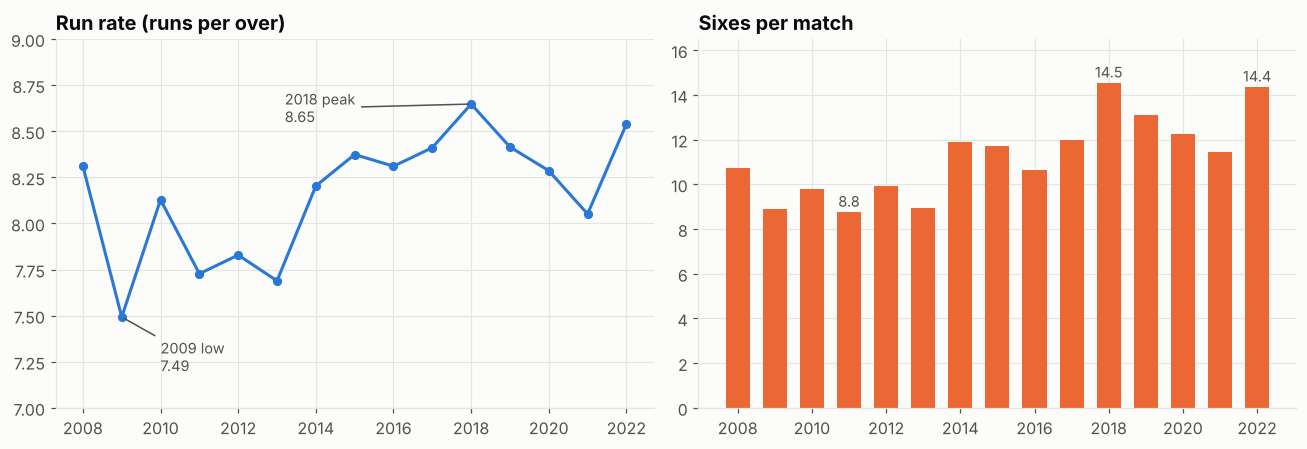

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(season.index, season.runs_per_over, color=C["blue"], marker="o", ms=5)
ax[0].set_title("Run rate (runs per over)"); ax[0].set_ylim(7, 9)
ax[0].annotate("2018 peak\n%.2f" % season.runs_per_over[2018], (2018, season.runs_per_over[2018]),
               xytext=(2013.2, 8.55), arrowprops=dict(arrowstyle="-", color=L.INK2), color=L.INK2, fontsize=9.5)
ax[0].annotate("2009 low\n%.2f" % season.runs_per_over[2009], (2009, season.runs_per_over[2009]),
               xytext=(2010, 7.2), arrowprops=dict(arrowstyle="-", color=L.INK2), color=L.INK2, fontsize=9.5)
ax[1].bar(season.index, season.sixes_per_match, color=C["orange"], width=0.65)
ax[1].set_title("Sixes per match")
for yr in (2011, 2018, 2022):
    ax[1].text(yr, season.sixes_per_match[yr] + 0.25, f"{season.sixes_per_match[yr]:.1f}", ha="center", fontsize=9.5, color=L.INK2)
ax[1].set_ylim(0, 16.5)
for a in ax: a.set_xticks(season.index[::2])
fig.tight_layout(); L.save(fig, "01_season_trends"); plt.show()

## 3. Batters — volume vs. efficiency

In [6]:
bat = balls.groupby("batter").agg(runs=("batter_runs", "sum"), balls_faced=("faced", "sum"),
                                  innings=("match_id", "nunique"))
bat["dismissals"] = balls[balls.is_wicket == 1].groupby("player_out").size().reindex(bat.index).fillna(0)
bat["strike_rate"] = bat.runs / bat.balls_faced * 100
bat["average"] = bat.runs / bat.dismissals.replace(0, np.nan)
bat["sixes"] = balls[balls.batter_runs == 6].groupby("batter").size().reindex(bat.index).fillna(0).astype(int)
bat["fours"] = balls[(balls.batter_runs == 4) & (balls.non_boundary == 0)].groupby("batter").size().reindex(bat.index).fillna(0).astype(int)
bat["boundary_%_of_runs"] = (bat.sixes * 6 + bat.fours * 4) / bat.runs * 100
top_bat = bat.sort_values("runs", ascending=False).head(10)
L.save_table(bat.sort_values("runs", ascending=False).head(50).round(2), "top50_batters")
top_bat.round(2)

,runs,balls_faced,innings,dismissals,strike_rate,average,sixes,fours,boundary_%_of_runs
batter,,,,,,,,,
V Kohli,6634,5133,215,183.0,129.24,36.25,219,580,54.78
S Dhawan,6244,4944,205,179.0,126.29,34.88,137,701,58.07
DA Warner,5883,4185,162,142.0,140.57,41.43,216,577,61.26
RG Sharma,5881,4529,221,194.0,129.85,30.31,241,519,59.89
SK Raina,5536,4046,200,171.0,136.83,32.37,204,506,58.67
AB de Villiers,5181,3411,170,130.0,151.89,39.85,253,414,61.26
CH Gayle,4997,3346,141,126.0,149.34,39.66,359,407,75.69
MS Dhoni,4978,3682,205,127.0,135.20,39.20,229,346,55.40
RV Uthappa,4954,3801,197,180.0,130.33,27.52,182,481,60.88


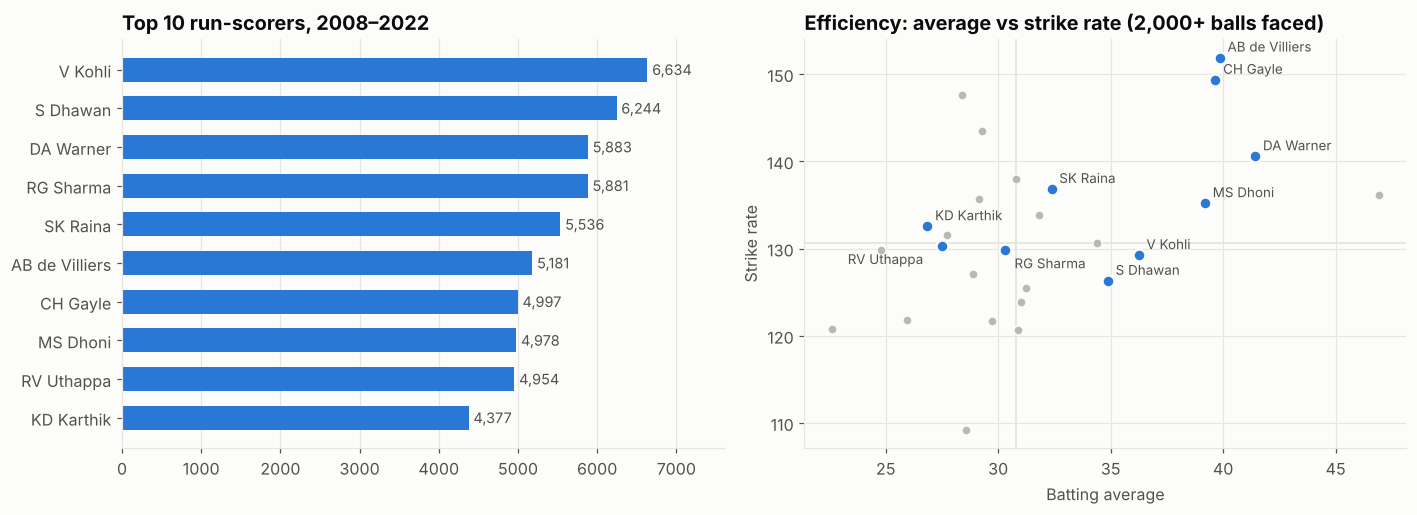

27 batters qualify; grey lines = median average / strike rate; blue = ten highest run-scorers


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
t = top_bat.iloc[::-1]
ax[0].barh(t.index, t.runs, color=C["blue"], height=0.62)
for y, v in enumerate(t.runs): ax[0].text(v + 60, y, f"{v:,}", va="center", fontsize=9.5, color=L.INK2)
ax[0].set_title("Top 10 run-scorers, 2008–2022"); ax[0].grid(axis="y", visible=False); ax[0].set_xlim(0, 7600)

q = bat[bat.balls_faced >= 2000]
ax[1].scatter(q.average, q.strike_rate, s=36, color=C["muted"], edgecolor=L.SURFACE, linewidth=1)
hi = q.sort_values("runs", ascending=False).head(10)
ax[1].scatter(hi.average, hi.strike_rate, s=60, color=C["blue"], edgecolor=L.SURFACE, linewidth=1.5)
off = {"RV Uthappa": (-62, -12), "RG Sharma": (6, -12)}
for n, r in hi.iterrows(): ax[1].annotate(n, (r.average, r.strike_rate), xytext=off.get(n, (5, 4)), textcoords="offset points", fontsize=8.8, color=L.INK2)
ax[1].axvline(q.average.median(), color=L.GRID, lw=1.2, zorder=0); ax[1].axhline(q.strike_rate.median(), color=L.GRID, lw=1.2, zorder=0)
ax[1].set_xlabel("Batting average"); ax[1].set_ylabel("Strike rate")
ax[1].set_title("Efficiency: average vs strike rate (2,000+ balls faced)")
fig.tight_layout(); L.save(fig, "02_top_batters"); plt.show()
print(f"{len(q)} batters qualify; grey lines = median average / strike rate; blue = ten highest run-scorers")

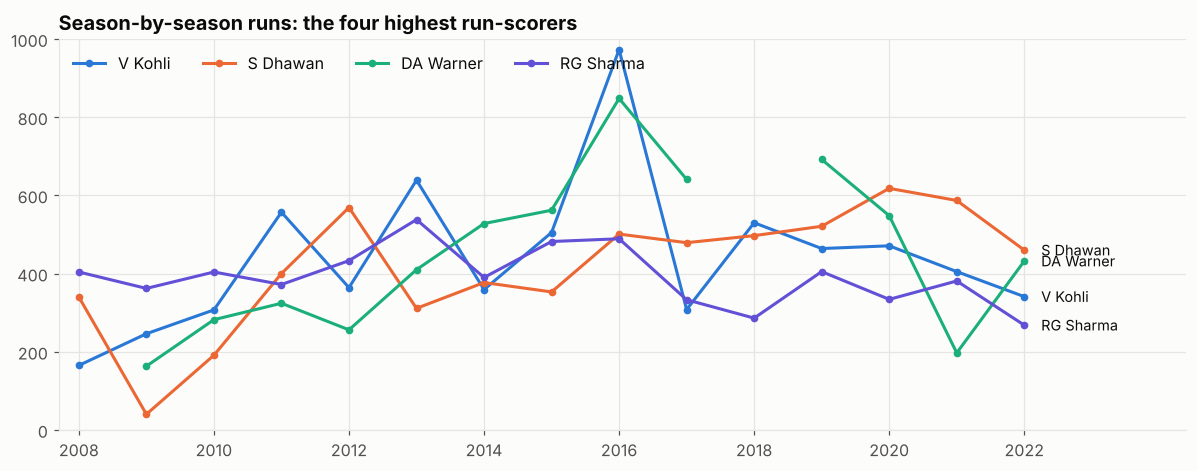

Best individual seasons:
season  batter       
2016    V Kohli          973
2022    JC Buttler       863
2016    DA Warner        848
2018    KS Williamson    735
2012    CH Gayle         733


In [8]:
# Head-to-head: season runs for the 4 highest scorers
four = top_bat.index[:4]
sub = balls[balls.batter.isin(four)]
pivot = sub.pivot_table(index="season", columns="batter", values="batter_runs", aggfunc="sum")[four]
pivot = pivot.where(sub.pivot_table(index="season", columns="batter", values="faced", aggfunc="sum")[four] > 0)  # gaps = did not play (e.g. Warner 2008 / 2018)
cols = [C["blue"], C["orange"], C["aqua"], C["violet"]]
fig, ax = plt.subplots(figsize=(11, 4.4))
for n, c in zip(four, cols):
    ax.plot(pivot.index, pivot[n], color=c, marker="o", ms=4, label=n)
    ax.text(2022.25, pivot[n].iloc[-1], n, color=L.INK, va="center", fontsize=9.5)
ax.set_xlim(2007.7, 2024.4); ax.set_xticks(range(2008, 2023, 2)); ax.set_title("Season-by-season runs: the four highest run-scorers")
ax.legend(loc="upper left", ncol=4); ax.set_ylim(0, 1000)
fig.tight_layout(); L.save(fig, "03_top4_season_runs"); plt.show()
best = balls.groupby(["season", "batter"]).batter_runs.sum().sort_values(ascending=False).head(5)
print("Best individual seasons:"); print(best.to_string())

## 4. Bowlers — wickets, economy and death-over specialists

In [9]:
bowl = balls.groupby("bowler").agg(wickets=("bowler_wicket", "sum"), runs_conceded=("bowler_runs", "sum"),
                                   legal_balls=("legal_delivery", "sum"), matches=("match_id", "nunique"))
bowl["economy"] = bowl.runs_conceded / bowl.legal_balls * 6
bowl["strike_rate"] = bowl.legal_balls / bowl.wickets.replace(0, np.nan)
bowl["average"] = bowl.runs_conceded / bowl.wickets.replace(0, np.nan)
top_bowl = bowl.sort_values("wickets", ascending=False).head(10)
L.save_table(bowl.sort_values("wickets", ascending=False).head(50).round(2), "top50_bowlers")
top_bowl.round(2)

,wickets,runs_conceded,legal_balls,matches,economy,strike_rate,average
bowler,,,,,,,
DJ Bravo,183,4360,3120,158,8.38,17.05,23.83
SL Malinga,170,3364,2828,122,7.14,16.64,19.79
A Mishra,166,3976,3245,154,7.35,19.55,23.95
YS Chahal,166,3624,2856,130,7.61,17.20,21.83
R Ashwin,157,4534,3900,181,6.98,24.84,28.88
PP Chawla,157,4301,3274,164,7.88,20.85,27.39
B Kumar,154,3971,3262,146,7.30,21.18,25.79
SP Narine,152,3831,3463,147,6.64,22.78,25.20
Harbhajan Singh,150,4030,3416,160,7.08,22.77,26.87


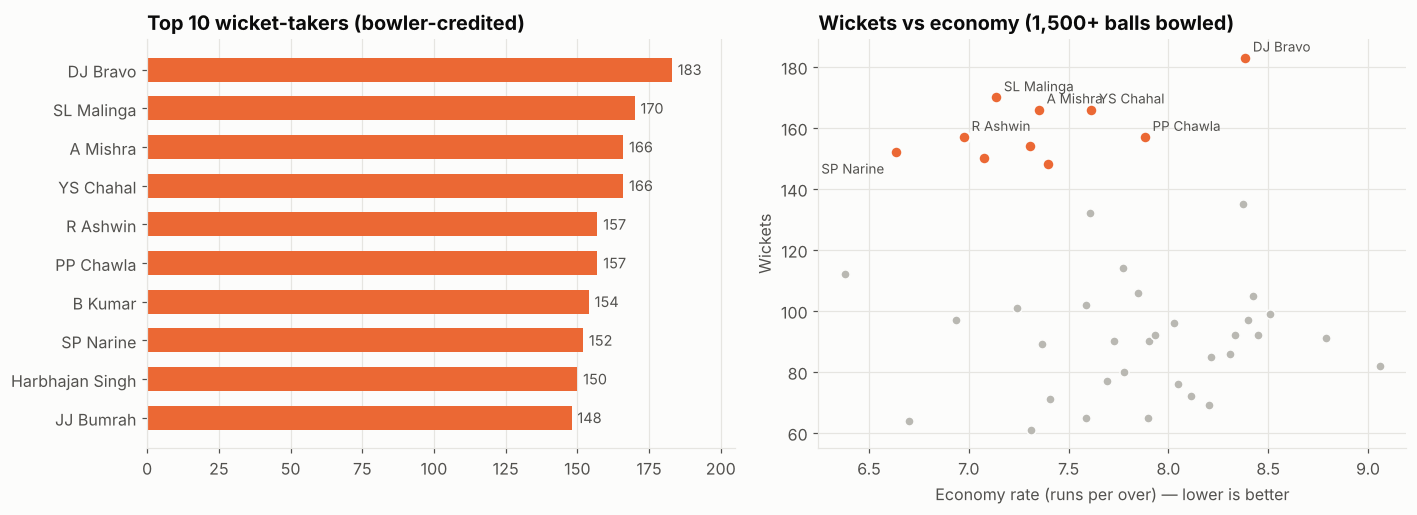

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
t = top_bowl.iloc[::-1]
ax[0].barh(t.index, t.wickets, color=C["orange"], height=0.62)
for y, v in enumerate(t.wickets): ax[0].text(v + 2, y, int(v), va="center", fontsize=9.5, color=L.INK2)
ax[0].set_title("Top 10 wicket-takers (bowler-credited)"); ax[0].grid(axis="y", visible=False); ax[0].set_xlim(0, 205)

q = bowl[bowl.legal_balls >= 1500]
ax[1].scatter(q.economy, q.wickets, s=36, color=C["muted"], edgecolor=L.SURFACE, linewidth=1)
hi = q.sort_values("wickets", ascending=False).head(10)
ax[1].scatter(hi.economy, hi.wickets, s=60, color=C["orange"], edgecolor=L.SURFACE, linewidth=1.5)
for n, r in hi.head(6).iterrows(): ax[1].annotate(n, (r.economy, r.wickets), xytext=(5, 4), textcoords="offset points", fontsize=8.8, color=L.INK2)
ax[1].annotate("SP Narine", (hi.loc["SP Narine"].economy, hi.loc["SP Narine"].wickets), xytext=(-8, -14), textcoords="offset points", fontsize=8.8, color=L.INK2, ha="right")
ax[1].set_xlabel("Economy rate (runs per over) — lower is better"); ax[1].set_ylabel("Wickets")
ax[1].set_title("Wickets vs economy (1,500+ balls bowled)")
fig.tight_layout(); L.save(fig, "04_top_bowlers"); plt.show()

In [11]:
death = balls[balls.phase.astype(str).str.startswith("Death")]
dd = death.groupby("bowler").agg(balls=("legal_delivery", "sum"), runs=("bowler_runs", "sum"), wickets=("bowler_wicket", "sum"))
dd = dd[dd.balls >= 300]; dd["economy"] = dd.runs / dd.balls * 6
dd = dd.sort_values("economy").head(10); L.save_table(dd.round(2), "death_over_specialists")
print("Best death-over (overs 16-20) economy, min 300 legal balls:"); dd.round(2)

Best death-over (overs 16-20) economy, min 300 legal balls:


,balls,runs,wickets,economy
bowler,,,,
SP Narine,949,1164,67,7.36
Rashid Khan,378,468,24,7.43
SL Malinga,1117,1464,108,7.86
R Ashwin,523,688,33,7.89
DW Steyn,634,877,50,8.30
JJ Bumrah,1146,1614,80,8.45
RA Jadeja,500,710,29,8.52
CH Morris,646,933,58,8.67
Mustafizur Rahman,448,650,25,8.71


## 5. Which phase drives the scoring boom?

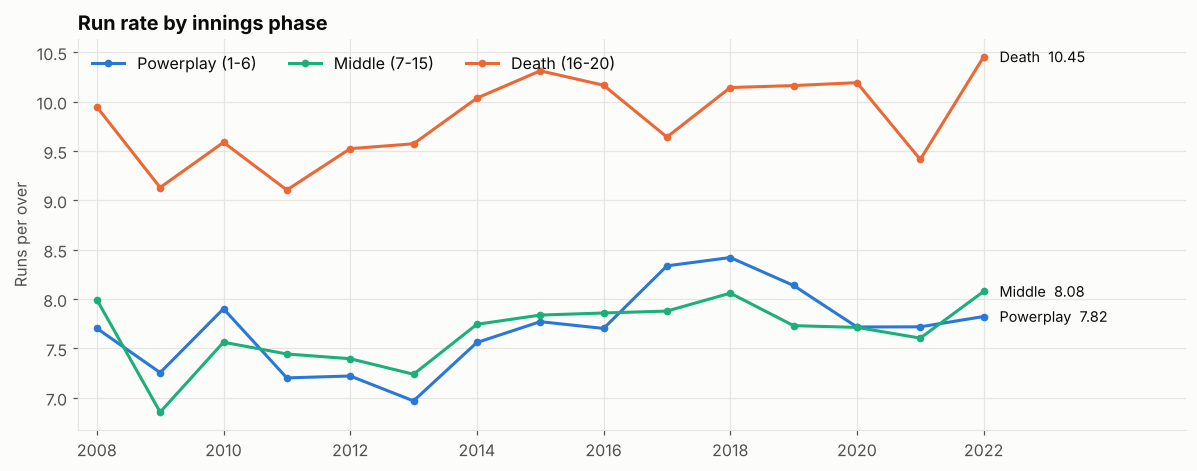

Average run rate 2008-12 vs 2018-22 by phase:
                 2008-12  2018-22  change
phase                                    
Powerplay (1-6)     7.46     7.96    0.51
Middle (7-15)       7.45     7.84    0.39
Death (16-20)       9.46    10.07    0.61


In [12]:
ph = balls.groupby(["season", "phase"], observed=True)[["total_runs", "legal_delivery"]].sum()
ph = (ph.total_runs / ph.legal_delivery * 6).unstack()
L.save_table(ph.round(2), "phase_run_rate")
fig, ax = plt.subplots(figsize=(11, 4.4))
for col, c in zip(ph.columns, [C["blue"], C["aqua"], C["orange"]]):
    ax.plot(ph.index, ph[col], color=c, marker="o", ms=4, label=col)
    ax.text(2022.25, ph[col].iloc[-1], f"{col.split(' (')[0]}  {ph[col].iloc[-1]:.2f}", va="center", fontsize=9.5)
ax.set_xlim(2007.7, 2025.2); ax.set_xticks(range(2008, 2023, 2)); ax.set_ylabel("Runs per over")
ax.set_title("Run rate by innings phase"); ax.legend(loc="upper left", ncol=3)
fig.tight_layout(); L.save(fig, "05_phase_run_rate"); plt.show()
print("Average run rate 2008-12 vs 2018-22 by phase:")
print(pd.DataFrame({"2008-12": ph.loc[2008:2012].mean(), "2018-22": ph.loc[2018:2022].mean()}).assign(change=lambda x: x["2018-22"] - x["2008-12"]).round(2))

## 6. How do batters get out?

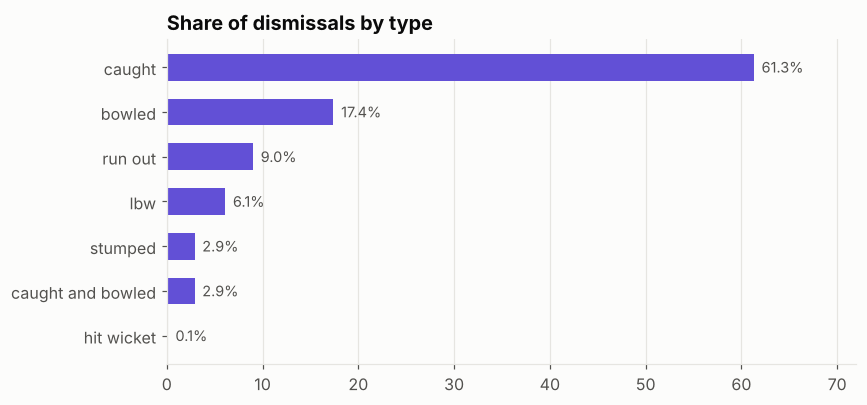

In [13]:
dk = balls[balls.is_wicket == 1].dismissal_kind.value_counts()
share = (dk / dk.sum() * 100).round(1)
L.save_table(share.to_frame("share_%"), "dismissal_types")
fig, ax = plt.subplots(figsize=(8, 3.8))
s = share.head(7).iloc[::-1]
ax.barh(s.index, s.values, color=C["violet"], height=0.6)
for y, v in enumerate(s.values): ax.text(v + 0.8, y, f"{v:.1f}%", va="center", fontsize=9.5, color=L.INK2)
ax.set_title("Share of dismissals by type"); ax.grid(axis="y", visible=False); ax.set_xlim(0, 72)
fig.tight_layout(); L.save(fig, "06_dismissals"); plt.show()

## 7. Match-level analysis (2008–2017)
The 2008–22 ball-by-ball file has no toss / winner / venue fields, so this section uses `matches.csv` (and joins `deliveries.csv` for first-innings totals). No-result matches are excluded where a winner is required.

In [14]:
decided = matches[~matches.no_result].copy()
toss_edge = decided.toss_win_match_win.mean() * 100
by_dec = decided.groupby("toss_decision").toss_win_match_win.agg(["mean", "count"]); by_dec["mean"] *= 100
print(f"Toss winner went on to win the match: {toss_edge:.1f}% of {len(decided)} decided matches")
print(by_dec.rename(columns={"mean": "toss-winner win %", "count": "matches"}).round(1))

# did the team batting first win?
fi = deliv[(deliv.inning == 1) & (deliv.is_super_over == 0)].groupby("match_id").total_runs.sum().rename("first_innings_runs")
decided = decided.merge(fi, left_on="id", right_index=True)
decided["bat_first_won"] = np.where(decided.toss_decision.eq("bat"), decided.toss_win_match_win, ~decided.toss_win_match_win)
print(f"\nBatting-first side won {decided.bat_first_won.mean()*100:.1f}% | chasing side won {100-decided.bat_first_won.mean()*100:.1f}%")

Toss winner went on to win the match: 51.3% of 633 decided matches
               toss-winner win %  matches
toss_decision                            
bat                         45.6      272
field                       55.7      361

Batting-first side won 44.9% | chasing side won 55.1%


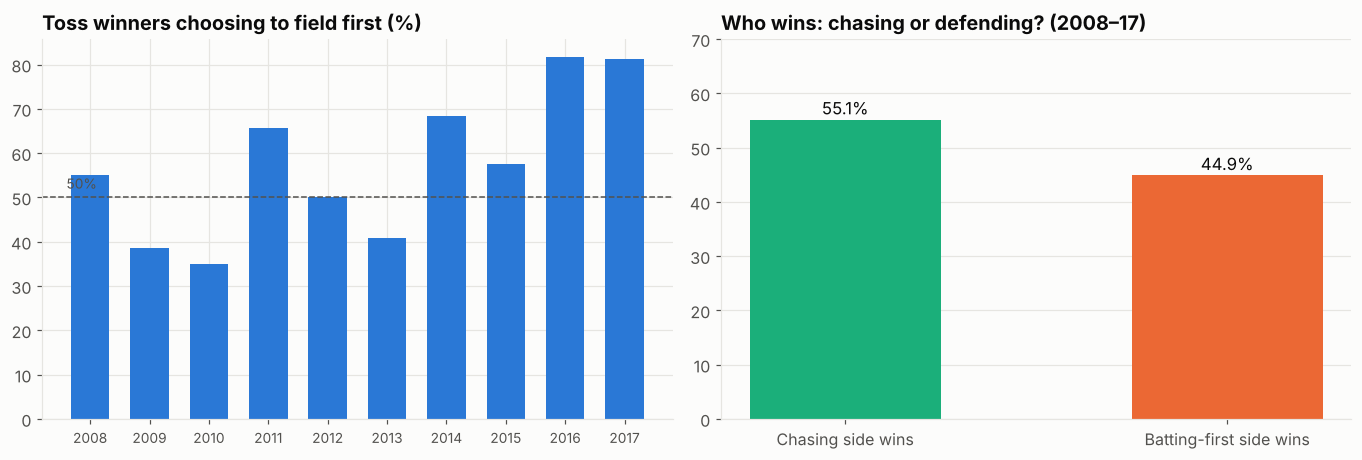

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
field_share = matches.groupby("season").toss_decision.apply(lambda x: (x == "field").mean() * 100)
ax[0].bar(field_share.index, field_share.values, color=C["blue"], width=0.65)
ax[0].axhline(50, color=L.INK2, lw=1, ls="--"); ax[0].text(2007.6, 52, "50%", color=L.INK2, fontsize=9)
ax[0].set_title("Toss winners choosing to field first (%)"); ax[0].set_xticks(field_share.index[::1]); ax[0].tick_params(axis="x", labelsize=9)

wr = decided.groupby("bat_first_won").size()
labels = ["Chasing side wins", "Batting-first side wins"]
vals = [wr.get(False, 0) / wr.sum() * 100, wr.get(True, 0) / wr.sum() * 100]
ax[1].bar(labels, vals, color=[C["aqua"], C["orange"]], width=0.5)
for i, v in enumerate(vals): ax[1].text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=11)
ax[1].set_ylim(0, 70); ax[1].set_title("Who wins: chasing or defending? (2008–17)"); ax[1].grid(axis="x", visible=False)
fig.tight_layout(); L.save(fig, "07_toss_and_chase"); plt.show()

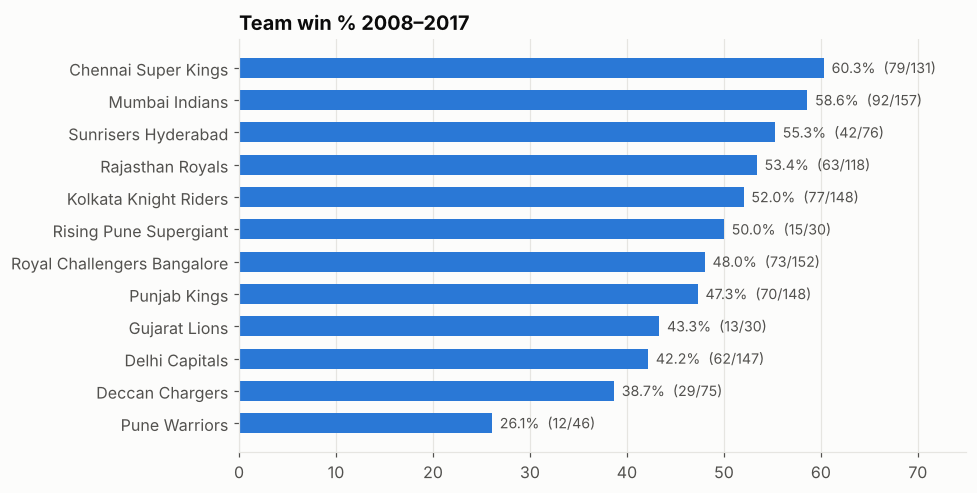

In [16]:
# Team win % (2008-17, % of matches played incl. no-results; teams with 30+ matches)
played = pd.concat([matches.team1, matches.team2]).value_counts()
wins = matches.winner.value_counts()
tw = pd.DataFrame({"played": played, "wins": wins}).fillna(0)
tw["win_pct"] = tw.wins / tw.played * 100
tw = tw[tw.played >= 30].sort_values("win_pct")
L.save_table(tw.sort_values("win_pct", ascending=False).round(1), "team_win_pct_2008_2017")
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(tw.index, tw.win_pct, color=C["blue"], height=0.62)
for y, (v, w, p) in enumerate(zip(tw.win_pct, tw.wins, tw.played)): ax.text(v + 0.8, y, f"{v:.1f}%  ({int(w)}/{int(p)})", va="center", fontsize=9.3, color=L.INK2)
ax.set_xlim(0, 75); ax.set_title("Team win % 2008–2017"); ax.grid(axis="y", visible=False)
fig.tight_layout(); L.save(fig, "08_team_win_pct"); plt.show()

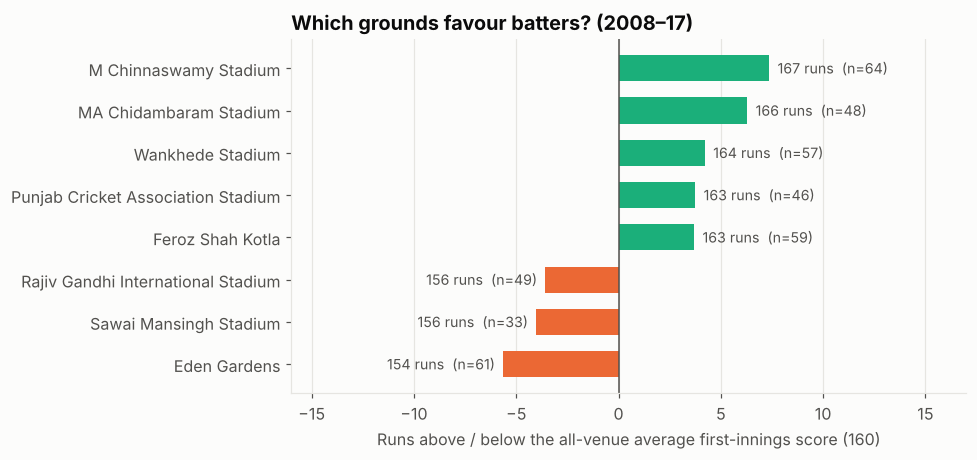

In [17]:
# Venues: average first-innings total vs the all-venue average (decided matches, venues with 30+ matches)
v = decided.groupby("venue").first_innings_runs.agg(["mean", "count"])
v = v[v["count"] >= 30].sort_values("mean")
overall = decided.first_innings_runs.mean()
L.save_table(v.sort_values("mean", ascending=False).round(1), "venue_avg_first_innings")
dev = v["mean"] - overall
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.barh(v.index, dev, color=[C["aqua"] if x > 0 else C["orange"] for x in dev], height=0.62)
ax.axvline(0, color=L.INK2, lw=1)
for y, (d_, m_, n) in enumerate(zip(dev, v["mean"], v["count"])):
    ax.text(d_ + (0.4 if d_ > 0 else -0.4), y, f"{m_:.0f} runs  (n={n})", va="center", ha="left" if d_ > 0 else "right", fontsize=9.3, color=L.INK2)
ax.set_xlim(-16, 17); ax.set_xlabel(f"Runs above / below the all-venue average first-innings score ({overall:.0f})")
ax.set_title("Which grounds favour batters? (2008–17)"); ax.grid(axis="y", visible=False)
fig.tight_layout(); L.save(fig, "09_venues"); plt.show()

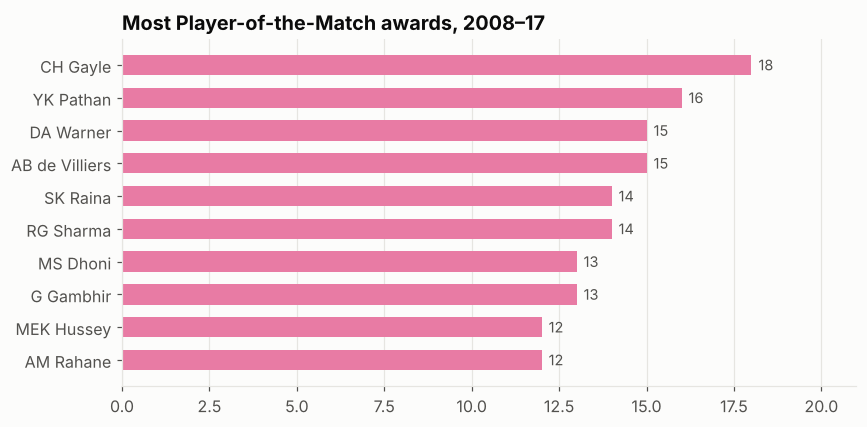

In [18]:
pom = matches.player_of_match.value_counts().head(10)
L.save_table(pom.to_frame("awards"), "player_of_match_top10")
fig, ax = plt.subplots(figsize=(8, 4))
p = pom.iloc[::-1]; ax.barh(p.index, p.values, color=C["magenta"], height=0.62)
for y, v in enumerate(p.values): ax.text(v + 0.2, y, int(v), va="center", fontsize=9.5, color=L.INK2)
ax.set_title("Most Player-of-the-Match awards, 2008–17"); ax.grid(axis="y", visible=False); ax.set_xlim(0, 21)
fig.tight_layout(); L.save(fig, "10_player_of_match"); plt.show()

## 8. Key findings
**Scoring & style of play**
- Run rate rose from a **7.49 runs/over low (2009)** to a **peak of 8.65 (2018)**, with another surge to 8.54 in 2022 (a 74-match season). Sixes per match climbed from ~8.8 (2011) to **~14.5 (2018)** and **14.4 (2022)**.
- The **death overs (16–20)** are consistently ~2 runs/over more productive than any other phase (10.07 in 2018–22) and gained the most since 2008–12 (**+0.61**), ahead of the powerplay (+0.51) and middle overs (+0.39). The powerplay spike of 2017–18 (8.3–8.4) has since faded back to ~7.8.

**Players**
- **V Kohli (6,634)** and **S Dhawan (6,244)** lead the run charts, but efficiency tells another story: **AB de Villiers (SR 151.9)** and **CH Gayle (149.3)** combine the highest strike rates with averages near 40, while **DA Warner** has the best average (41.4) of the top ten scorers.
- The best individual season is **Kohli's 973 runs in 2016**, followed by Buttler's 863 in 2022 and Warner's 848 in 2016.
- **DJ Bravo (183)** and **SL Malinga (170)** lead wicket-takers. **SP Narine** is the standout for economy (**6.64** with 152 wickets); he and **Rashid Khan** (7.4) are also the most economical bowlers in the death overs (min. 300 balls).
- Batters are mostly out **caught (61%)** or **bowled (17%)**; run-outs are 9%.

**Match outcomes (2008–17)**
- The toss is only a slight edge: the toss winner won **51.3%** of decided matches. But **chasing** wins **55.1%** of the time, and toss winners who chose to field won 55.7% vs 45.6% for those who batted. Teams noticed: the share of toss winners choosing to field rose from ~35–40% (2009–10) to **>80% (2016–17)**.
- **CSK (60.3%)** and **Mumbai Indians (58.6%)** have the best win rates; Mumbai also has the most wins (92).
- **M. Chinnaswamy (Bengaluru)** is the highest-scoring ground (avg first innings ~167), **Eden Gardens** the lowest (~154) — a ~13-run gap that matters when setting targets.
- **Chris Gayle** has the most Player-of-the-Match awards (18), then Yusuf Pathan (16).

## 9. Limitations & next steps
- Seasons for the 2008–22 file are derived from match-ID blocks (validated against official match counts per season, but not against dates).
- Toss / winner / venue analysis stops at 2017 because the 2008–22 ball file has no match metadata; joining a newer `matches` file would extend it to 2022.
- Batting average = runs ÷ dismissals (not-outs excluded from the divisor); strike rate excludes wides from balls faced (the small `batter.csv` in the original folder included them, so Kohli's SR there is 126.0 vs 129.2 here).
- The toss/chase relationship is correlational (dew, pitch, and team strength are not controlled for).
- Next: win-probability model from ball-by-ball state, player-vs-bowler-type matchups, a Power BI / Streamlit dashboard on top of `outputs/tables/`.